# `tile_tpms`

Tiles a 3D triply periodic minimal surface (TPMS) unit cell to build a larger periodic or reflected domain.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import porespy as ps

ps.visualization.set_mpl_style()

## `im` and `n`

Generate a single TPMS unit cell with `tpms_unit_cell` and repeat it using `tile_tpms`. Passing a single integer `n` repeats the unit cell equally along all three axes.

Unit cell shape: (50, 50, 50)
Tiled shape:     (150, 150, 150)


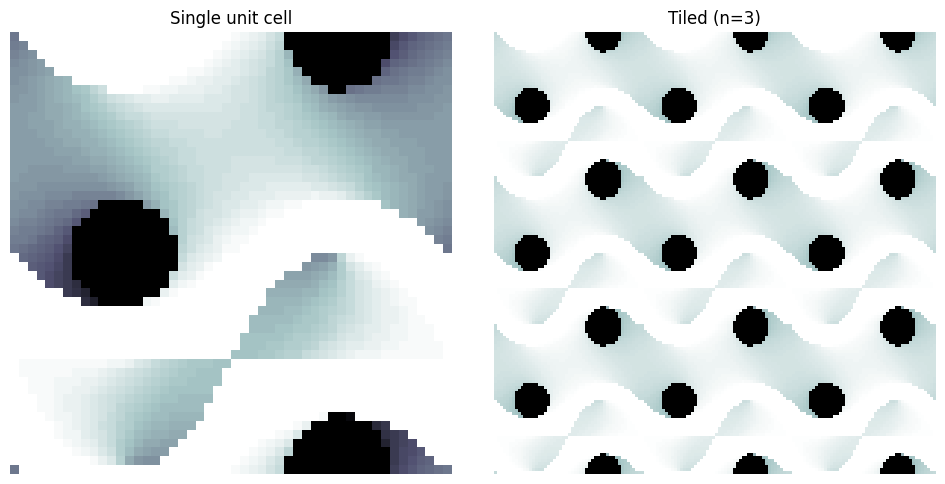

In [2]:
im1 = ps.generators.tpms_unit_cell(shape=50)
im2 = ps.generators.tile_tpms(im=im1, n=3)

print(f"Unit cell shape: {im1.shape}")
print(f"Tiled shape:     {im2.shape}")

fig, ax = plt.subplots(1, 2, figsize=[10, 5])
ax[0].imshow(ps.visualization.sem(im1), cmap=plt.cm.bone)
ax[0].set_title("Single unit cell")
ax[0].axis(False)
ax[1].imshow(ps.visualization.sem(im2), cmap=plt.cm.bone)
ax[1].set_title("Tiled (n=3)")
ax[1].axis(False);

Passing a sequence for `n` controls the number of repetitions independently along each axis:

Anisotropic tiled shape: (150, 100, 50)


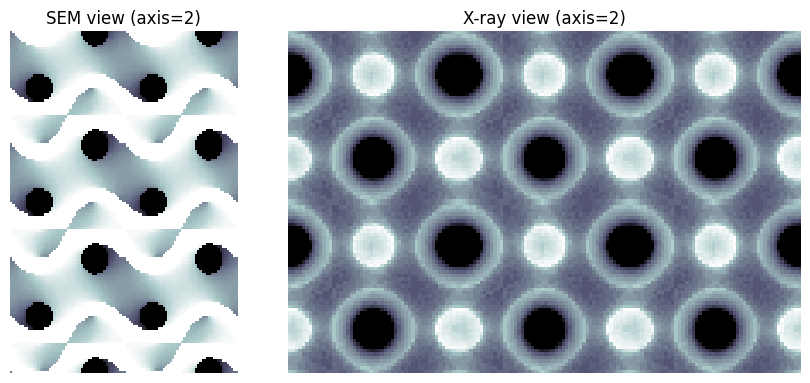

In [3]:
im3 = ps.generators.tile_tpms(im=im1, n=(3, 2, 1))
print(f"Anisotropic tiled shape: {im3.shape}")

fig, ax = plt.subplots(1, 2, figsize=[10, 4])
ax[0].imshow(ps.visualization.sem(im3, axis=2), cmap=plt.cm.bone)
ax[0].set_title("SEM view (axis=2)")
ax[0].axis(False)
ax[1].imshow(ps.visualization.xray(im3, axis=2), cmap=plt.cm.bone)
ax[1].set_title("X-ray view (axis=2)")
ax[1].axis(False);

## `mode`

By default, `mode='periodic'` repeats the unit cell by simple copying. Setting `mode='reflect'` mirrors the image at each tile boundary so features meet smoothly across tile edges even for non-periodic sub-volumes.

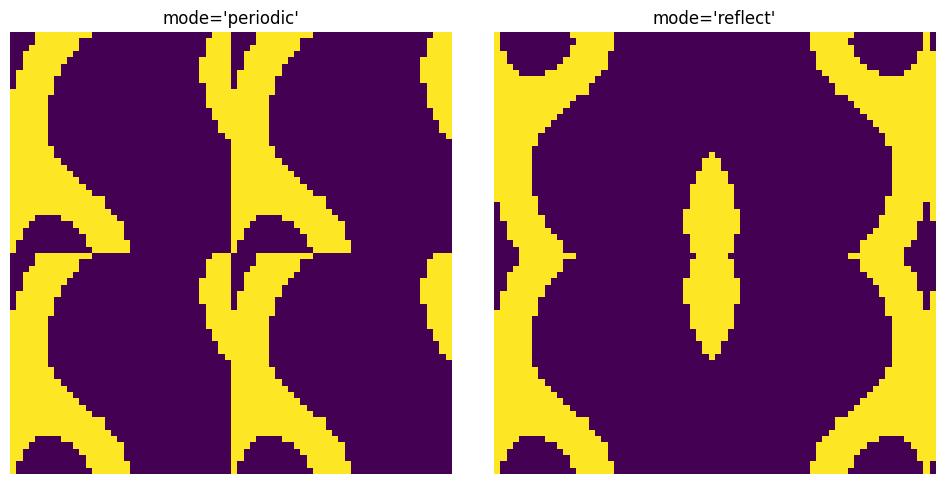

In [4]:
crop = im1[:35, :35, :35]
im_per = ps.generators.tile_tpms(im=crop, n=(2, 2, 1), mode="periodic")
im_ref = ps.generators.tile_tpms(im=crop, n=(2, 2, 1), mode="reflect")

fig, ax = plt.subplots(1, 2, figsize=[10, 5])
ax[0].imshow(im_per[:, :, 15], origin="lower", interpolation="none")
ax[0].set_title("mode='periodic'")
ax[0].axis(False)
ax[1].imshow(im_ref[:, :, 15], origin="lower", interpolation="none")
ax[1].set_title("mode='reflect'")
ax[1].axis(False);